<b>Example 3: Breast Cancer Dataset</b>

---

Section 01: Import Libraries

In [41]:
import pickle   
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate

from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score  
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.tree import DecisionTreeClassifier  
from sklearn.tree import _tree

from sklearn.neighbors import KNeighborsClassifier 

---

Section 02: Preprocess Data

In [42]:
# Load dataset
df_main = pd.read_csv('wdbc.csv')
df_main

,id,diagnosis,m_radius,m_texture,m_perimeter,m_area,m_smoothness,m_compactness,m_concavity,m_concave_points,...,w_radius,w_texture,w_perimeter,w_area,w_smoothness,w_compactness,w_concavity,w_concave_points,w_symmetry,w_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


<small>2.1 Assign data type</small>

In [43]:
# Check data types
df_main.dtypes

id                        int64
diagnosis                object
m_radius                float64
m_texture               float64
m_perimeter             float64
m_area                  float64
m_smoothness            float64
m_compactness           float64
m_concavity             float64
m_concave_points        float64
m_symmetry              float64
m_fractal_dimension     float64
se_radius               float64
se_texture              float64
se_perimeter            float64
se_area                 float64
se_smoothness           float64
se_compactness          float64
se_concavity            float64
se_concave_points       float64
se_symmetry             float64
se_fractal_dimension    float64
w_radius                float64
w_texture               float64
w_perimeter             float64
w_area                  float64
w_smoothness            float64
w_compactness           float64
w_concavity             float64
w_concave_points        float64
w_symmetry              float64
w_fracta

In [44]:
# Assign selected data types
df_main['id'] = df_main['id'].astype(object)
df_main['diagnosis'] = df_main['diagnosis'].astype('category')
df_main.dtypes

id                        object
diagnosis               category
m_radius                 float64
m_texture                float64
m_perimeter              float64
m_area                   float64
m_smoothness             float64
m_compactness            float64
m_concavity              float64
m_concave_points         float64
m_symmetry               float64
m_fractal_dimension      float64
se_radius                float64
se_texture               float64
se_perimeter             float64
se_area                  float64
se_smoothness            float64
se_compactness           float64
se_concavity             float64
se_concave_points        float64
se_symmetry              float64
se_fractal_dimension     float64
w_radius                 float64
w_texture                float64
w_perimeter              float64
w_area                   float64
w_smoothness             float64
w_compactness            float64
w_concavity              float64
w_concave_points         float64
w_symmetry

<small>2.2 Normalized and Encode data</small>

In [45]:
df_main['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [46]:
df_main['diagnosis'] = df_main['diagnosis'].map({'M':1, 'B':0})
df_main['diagnosis'].value_counts() 

diagnosis
0    357
1    212
Name: count, dtype: int64

In [47]:
# Check data statistics
df_main.describe()

,m_radius,m_texture,m_perimeter,m_area,m_smoothness,m_compactness,m_concavity,m_concave_points,m_symmetry,m_fractal_dimension,...,w_radius,w_texture,w_perimeter,w_area,w_smoothness,w_compactness,w_concavity,w_concave_points,w_symmetry,w_fractal_dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [48]:
# Normalize data
scaler = MinMaxScaler()

df_main['m_radius'] = scaler.fit_transform(df_main[['m_radius']])
df_main['m_texture'] = scaler.fit_transform(df_main[['m_texture']])
df_main['m_perimeter'] = scaler.fit_transform(df_main[['m_perimeter']])
df_main['m_area'] = scaler.fit_transform(df_main[['m_area']])
df_main['m_smoothness'] = scaler.fit_transform(df_main[['m_smoothness']])
df_main['m_compactness'] = scaler.fit_transform(df_main[['m_compactness']])
df_main['m_concavity'] = scaler.fit_transform(df_main[['m_concavity']])
df_main['m_concave_points'] = scaler.fit_transform(df_main[['m_concave_points']])
df_main['m_symmetry'] = scaler.fit_transform(df_main[['m_symmetry']])
df_main['m_fractal_dimension'] = scaler.fit_transform(df_main[['m_fractal_dimension']])

df_main['se_radius'] = scaler.fit_transform(df_main[['se_radius']])
df_main['se_texture'] = scaler.fit_transform(df_main[['se_texture']])
df_main['se_perimeter'] = scaler.fit_transform(df_main[['se_perimeter']])
df_main['se_area'] = scaler.fit_transform(df_main[['se_area']])
df_main['se_smoothness'] = scaler.fit_transform(df_main[['se_smoothness']])
df_main['se_compactness'] = scaler.fit_transform(df_main[['se_compactness']])
df_main['se_concavity'] = scaler.fit_transform(df_main[['se_concavity']])
df_main['se_concave_points'] = scaler.fit_transform(df_main[['se_concave_points']])
df_main['se_symmetry'] = scaler.fit_transform(df_main[['se_symmetry']])
df_main['se_fractal_dimension'] = scaler.fit_transform(df_main[['se_fractal_dimension']])

df_main['w_radius'] = scaler.fit_transform(df_main[['w_radius']])
df_main['w_texture'] = scaler.fit_transform(df_main[['w_texture']])
df_main['w_perimeter'] = scaler.fit_transform(df_main[['w_perimeter']])
df_main['w_area'] = scaler.fit_transform(df_main[['w_area']])
df_main['w_smoothness'] = scaler.fit_transform(df_main[['w_smoothness']])
df_main['w_compactness'] = scaler.fit_transform(df_main[['w_compactness']])
df_main['w_concavity'] = scaler.fit_transform(df_main[['w_concavity']])
df_main['w_concave_points'] = scaler.fit_transform(df_main[['w_concave_points']])
df_main['w_symmetry'] = scaler.fit_transform(df_main[['w_symmetry']])
df_main['w_fractal_dimension'] = scaler.fit_transform(df_main[['w_fractal_dimension']])

df_main

# # Normalized data (another coding style)
# cols_to_normalize = [
#     'm_radius', 'm_texture', 'm_perimeter', 'm_area',
#     'm_smoothness', 'm_compactness', 'm_concavity', 'm_concave_points',
#     'm_symmetry', 'm_fractal_dimension', 'se_radius', 'se_texture',
#     'se_perimeter', 'se_area', 'se_smoothness', 'se_compactness',
#     'se_concavity', 'se_concave_points', 'se_symmetry',
#     'se_fractal_dimension', 'w_radius', 'w_texture', 'w_perimeter',
#     'w_area', 'w_smoothness', 'w_compactness', 'w_concavity',
#     'w_concave_points', 'w_symmetry', 'w_fractal_dimension'
# ]

# scaler = MinMaxScaler()
# df_main[cols_to_normalize] = scaler.fit_transform(df_main[cols_to_normalize])
# df_main

,id,diagnosis,m_radius,m_texture,m_perimeter,m_area,m_smoothness,m_compactness,m_concavity,m_concave_points,...,w_radius,w_texture,w_perimeter,w_area,w_smoothness,w_compactness,w_concavity,w_concave_points,w_symmetry,w_fractal_dimension
0,842302,1,0.521037,0.022658,0.545989,0.363733,0.593753,0.792037,0.703140,0.731113,...,0.620776,0.141525,0.668310,0.450698,0.601136,0.619292,0.568610,0.912027,0.598462,0.418864
1,842517,1,0.643144,0.272574,0.615783,0.501591,0.289880,0.181768,0.203608,0.348757,...,0.606901,0.303571,0.539818,0.435214,0.347553,0.154563,0.192971,0.639175,0.233590,0.222878
2,84300903,1,0.601496,0.390260,0.595743,0.449417,0.514309,0.431017,0.462512,0.635686,...,0.556386,0.360075,0.508442,0.374508,0.483590,0.385375,0.359744,0.835052,0.403706,0.213433
3,84348301,1,0.210090,0.360839,0.233501,0.102906,0.811321,0.811361,0.565604,0.522863,...,0.248310,0.385928,0.241347,0.094008,0.915472,0.814012,0.548642,0.884880,1.000000,0.773711
4,84358402,1,0.629893,0.156578,0.630986,0.489290,0.430351,0.347893,0.463918,0.518390,...,0.519744,0.123934,0.506948,0.341575,0.437364,0.172415,0.319489,0.558419,0.157500,0.142595
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,1,0.690000,0.428813,0.678668,0.566490,0.526948,0.296055,0.571462,0.690358,...,0.623266,0.383262,0.576174,0.452664,0.461137,0.178527,0.328035,0.761512,0.097575,0.105667
565,926682,1,0.622320,0.626987,0.604036,0.474019,0.407782,0.257714,0.337395,0.486630,...,0.560655,0.699094,0.520892,0.379915,0.300007,0.159997,0.256789,0.559450,0.198502,0.074315
566,926954,1,0.455251,0.621238,0.445788,0.303118,0.288165,0.254340,0.216753,0.263519,...,0.393099,0.589019,0.379949,0.230731,0.282177,0.273705,0.271805,0.487285,0.128721,0.151909
567,927241,1,0.644564,0.663510,0.665538,0.475716,0.588336,0.790197,0.823336,0.755467,...,0.633582,0.730277,0.668310,0.402035,0.619626,0.815758,0.749760,0.910653,0.497142,0.452315


<small>2.3 Create training and test data</small>

In [49]:
X = df_main.drop(['id', 'diagnosis'], axis=1)
y = df_main['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=45)

In [50]:
print("----------- Training Data -----------")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))
print("\n------------ Test Data --------------")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

----------- Training Data -----------
diagnosis
0    237
1    144
Name: count, dtype: int64
diagnosis
0    0.622047
1    0.377953
Name: proportion, dtype: float64

------------ Test Data --------------
diagnosis
0    120
1     68
Name: count, dtype: int64
diagnosis
0    0.638298
1    0.361702
Name: proportion, dtype: float64


---

Section 03: Cross Validation

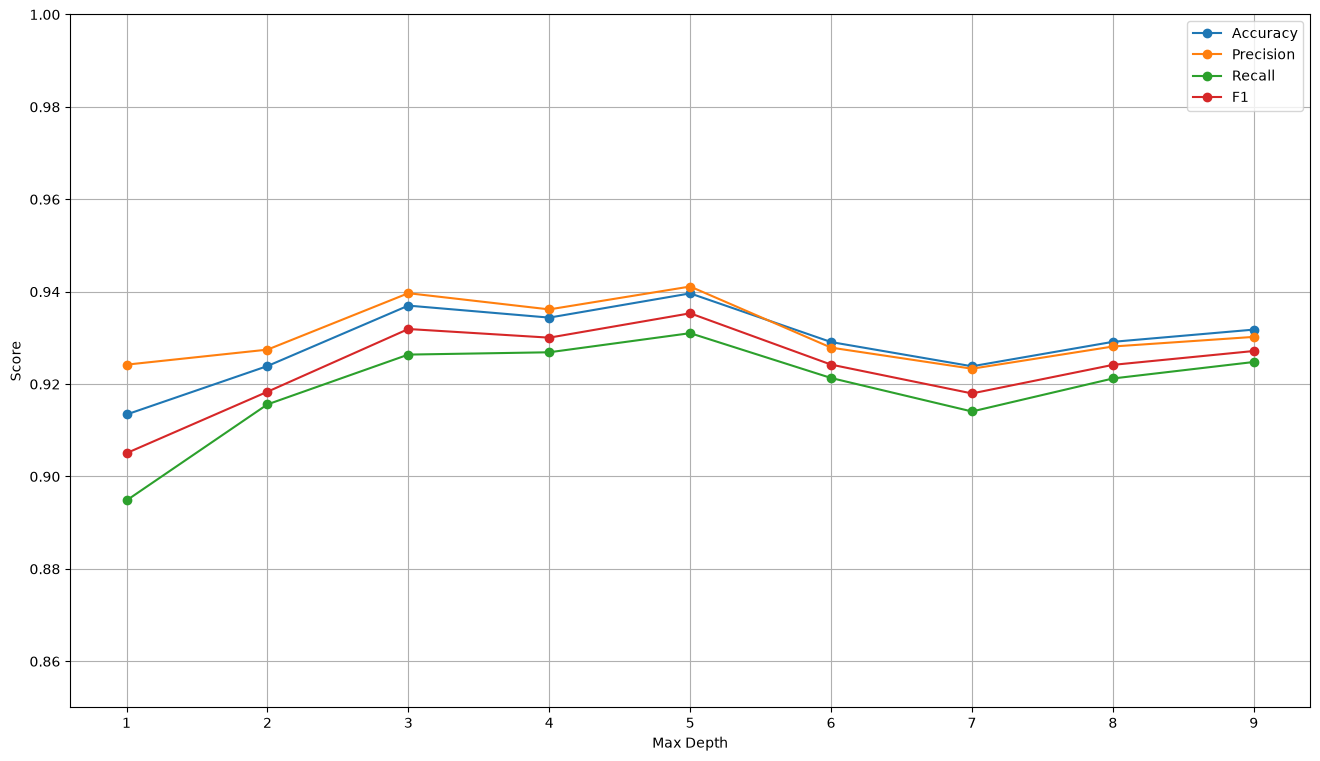

In [51]:
# Observe max_depth
max_depth = []
accuracy = []
precision = []
recall = []
f1_macro = []

# Observe algorithm
criterion = 'gini'
#criterion = 'entropy'

for i in range(1, 10):
    clf = DecisionTreeClassifier(criterion=criterion, max_depth=i, random_state=42)
    scoring = {
        'accuracy': 'accuracy',
        'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
        'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
        'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
    }
    scores = cross_validate(clf, X_train, y_train, cv=7, scoring=scoring)

    max_depth.append(i)
    accuracy.append(scores['test_accuracy'].mean())
    precision.append(scores['test_precision_macro'].mean())
    recall.append(scores['test_recall_macro'].mean())
    f1_macro.append(scores['test_f1_macro'].mean())


fig, ax = plt.subplots(figsize=(16, 9))
ax.plot(max_depth, accuracy, marker='o')
ax.plot(max_depth, precision, marker='o')
ax.plot(max_depth, recall, marker='o')
ax.plot(max_depth, f1_macro, marker='o')

ax.legend(['Accuracy', 'Precision', 'Recall', 'F1'])
ax.set_xlabel("Max Depth")
ax.set_ylabel("Score")
ax.set_ylim([0.85, 1])
ax.grid()
plt.show()

<small>Note: select 'gini' with depth = 5<small> 

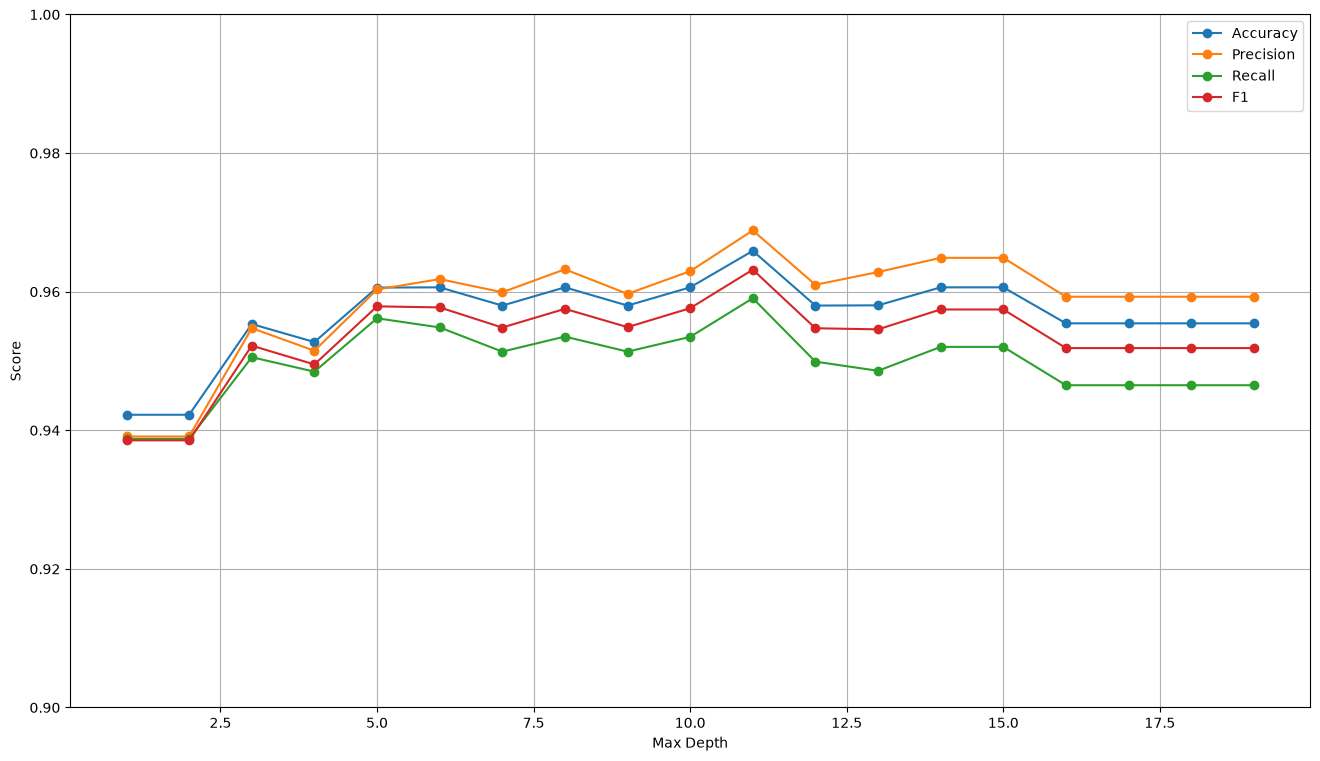

In [52]:
# Observe max_depth
max_depth = []
accuracy = []
precision = []
recall = []
f1_macro = []

# Observe algorithm
#criterion = 'uniform'
criterion = 'distance'

for i in range(1, 20):
    clf = KNeighborsClassifier(n_neighbors=i, weights=criterion)
    scoring = {
        'accuracy': 'accuracy',
        'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
        'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
        'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
    }
    scores = cross_validate(clf, X_train, y_train, cv=5, scoring=scoring)

    max_depth.append(i)
    accuracy.append(scores['test_accuracy'].mean())
    precision.append(scores['test_precision_macro'].mean())
    recall.append(scores['test_recall_macro'].mean())
    f1_macro.append(scores['test_f1_macro'].mean())


fig, ax = plt.subplots(figsize=(16, 9))
ax.plot(max_depth, accuracy, marker='o')
ax.plot(max_depth, precision, marker='o')
ax.plot(max_depth, recall, marker='o')
ax.plot(max_depth, f1_macro, marker='o')

ax.legend(['Accuracy', 'Precision', 'Recall', 'F1'])
ax.set_xlabel("Max Depth")
ax.set_ylabel("Score")
ax.set_ylim([0.9, 1])
ax.grid()
plt.show()

<small>Note: Select "distance" with K = 11</small>

---

Section 04: Create Model

              precision    recall  f1-score   support

     Class 0       0.94      0.98      0.96       120
     Class 1       0.97      0.90      0.93        68

    accuracy                           0.95       188
   macro avg       0.96      0.94      0.95       188
weighted avg       0.95      0.95      0.95       188



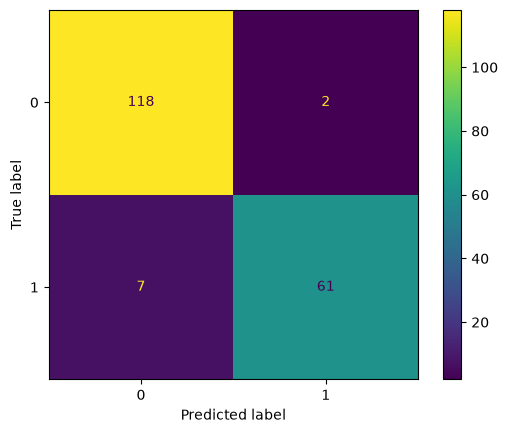

In [53]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=5)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
target_names = ['Class 0','Class 1']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot();

              precision    recall  f1-score   support

     Class 0       0.97      1.00      0.98       120
     Class 1       1.00      0.94      0.97        68

    accuracy                           0.98       188
   macro avg       0.98      0.97      0.98       188
weighted avg       0.98      0.98      0.98       188



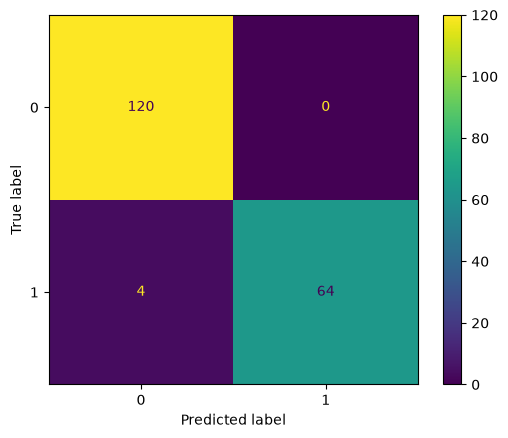

In [54]:
clf = KNeighborsClassifier(n_neighbors=11, weights='distance')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
target_names = ['Class 0','Class 1']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot();

In [55]:
filename = "model_01.mod"
pickle.dump(clf, open(filename, 'wb'))

---

Section 05: Analyze Decision Trees Model

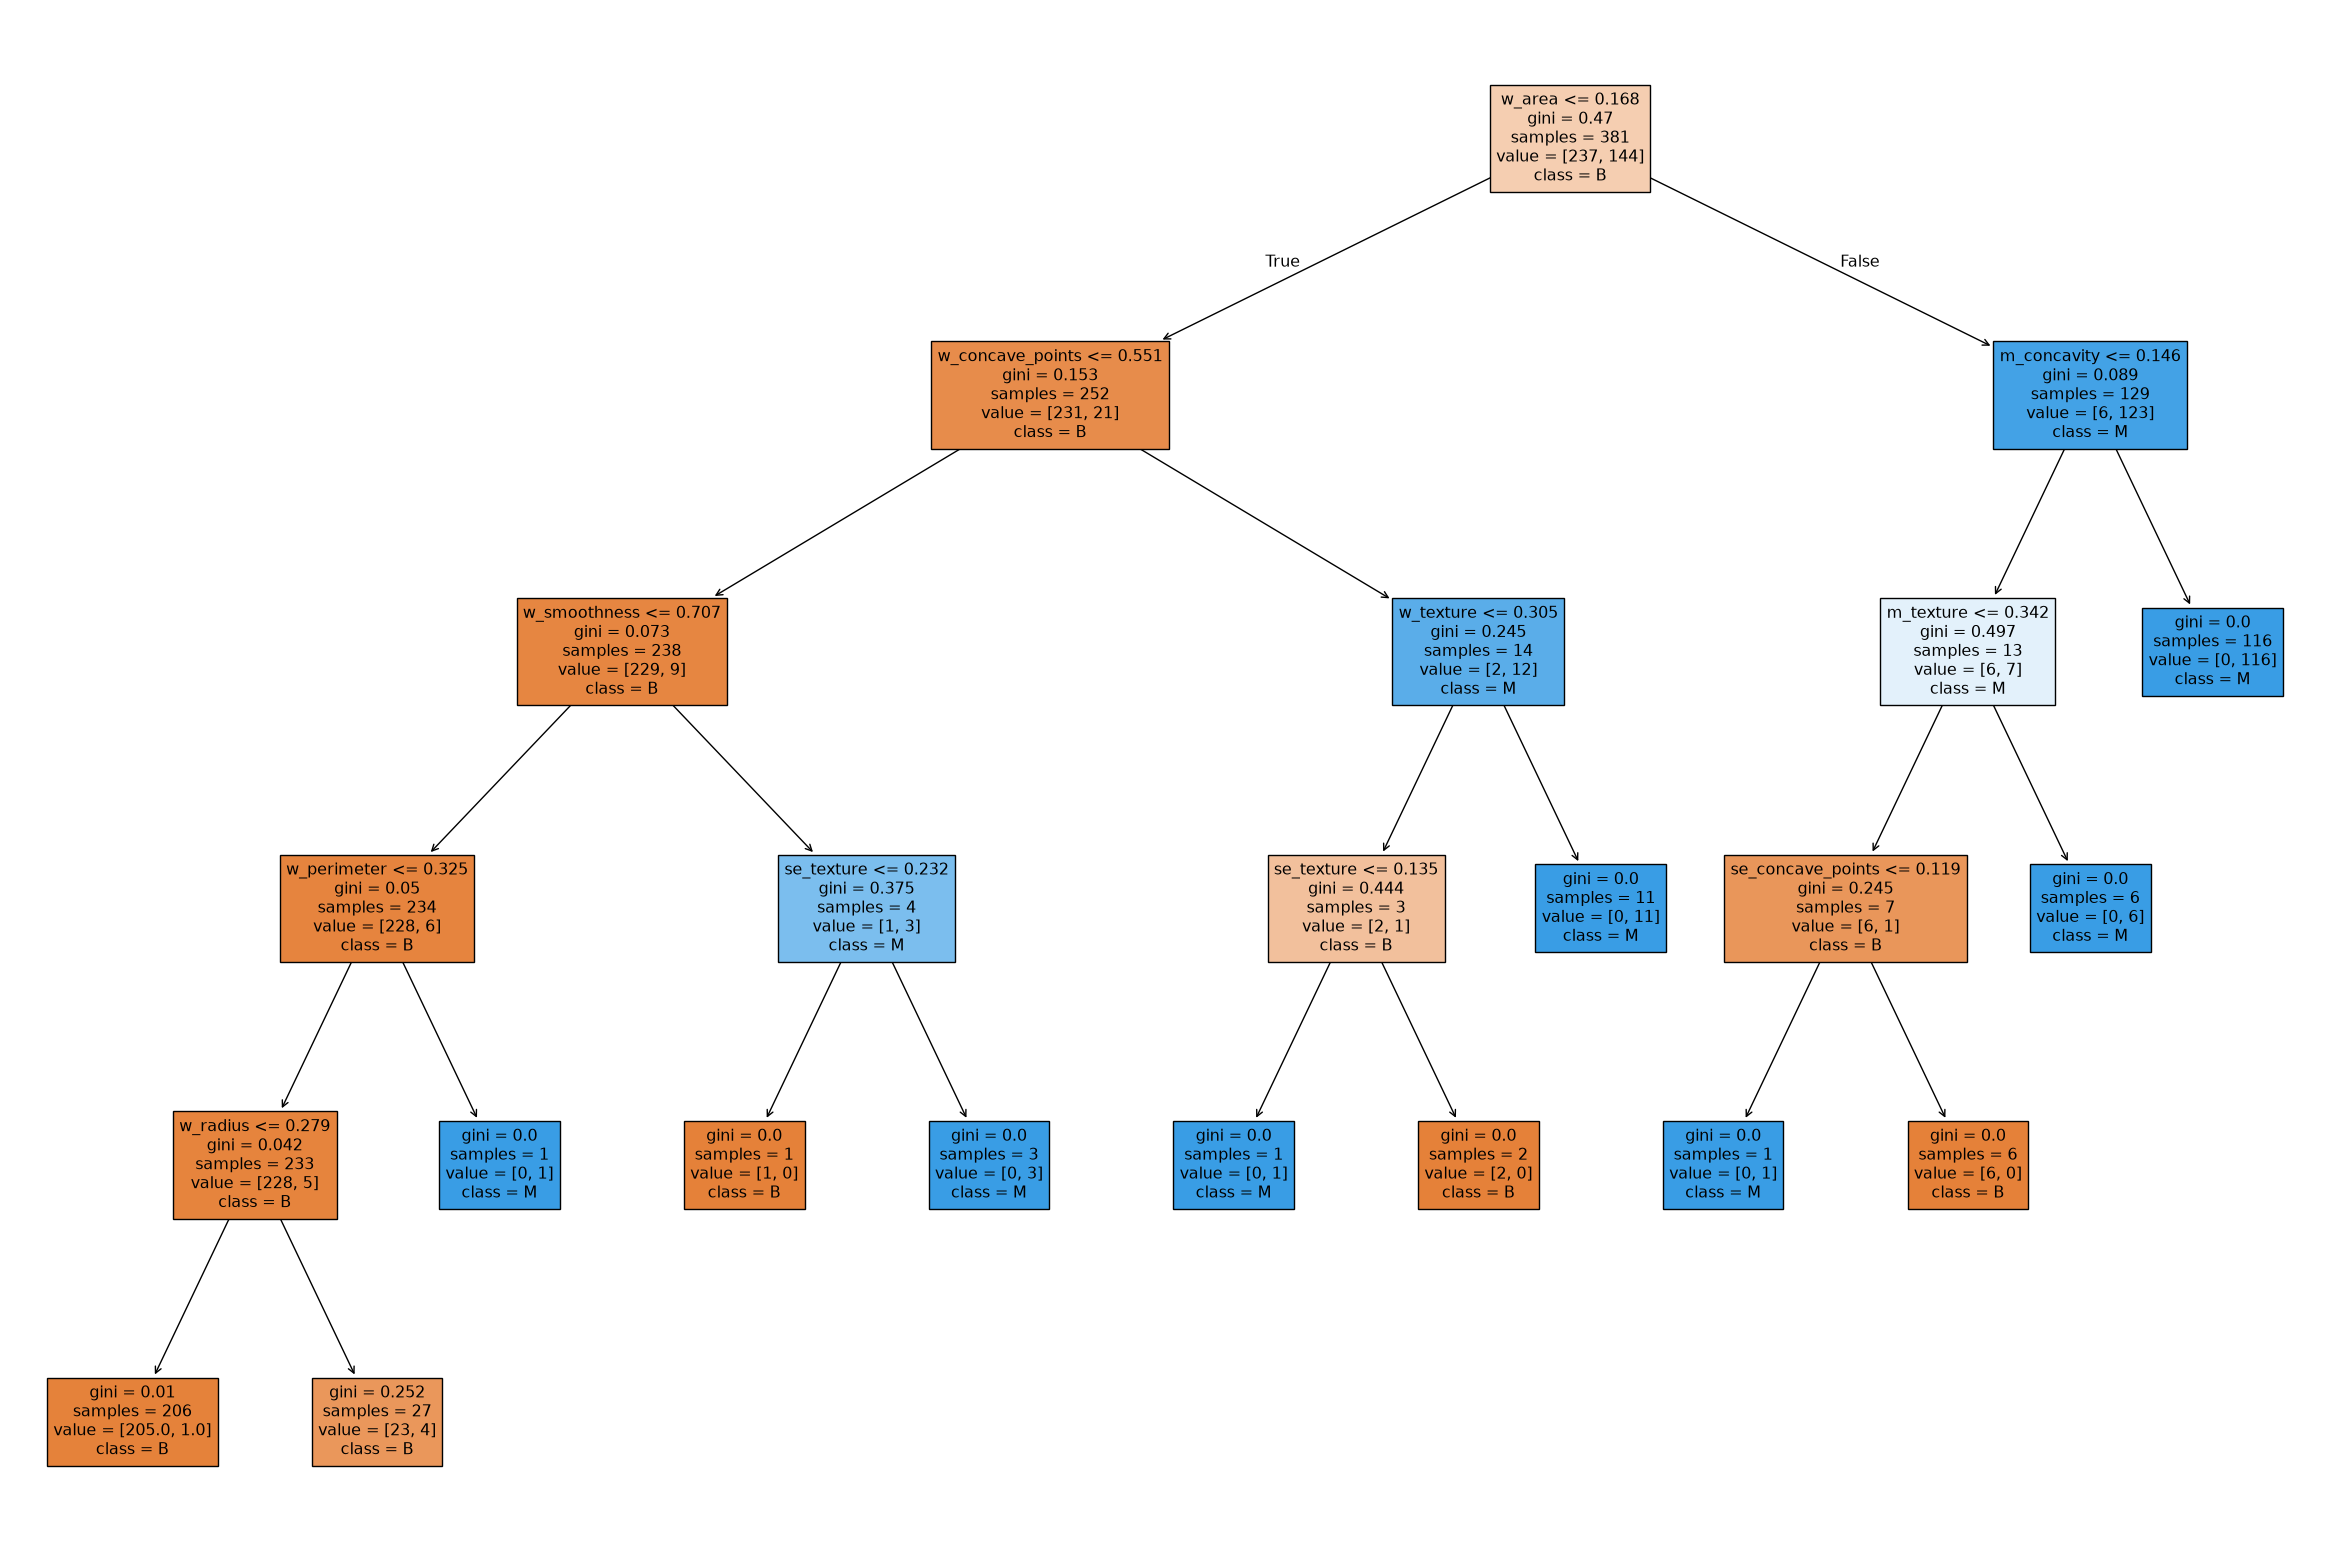

In [59]:
from sklearn import tree

# 1. เทรนโมเดลด้วย DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

plt.figure(figsize=(30, 20))  
tree.plot_tree(
    clf,
    feature_names=['m_radius', 'm_texture', 'm_perimeter', 'm_area', 'm_smoothness',
                   'm_compactness', 'm_concavity', 'm_concave_points', 'm_symmetry', 
                   'm_fractal_dimension', 'se_radius', 'se_texture', 'se_perimeter', 
                   'se_area', 'se_smoothness', 'se_compactness', 'se_concavity',
                   'se_concave_points', 'se_symmetry', 'se_fractal_dimension', 
                   'w_radius', 'w_texture', 'w_perimeter', 'w_area', 'w_smoothness', 
                   'w_compactness', 'w_concavity', 'w_concave_points', 'w_symmetry', 
                   'w_fractal_dimension'],
    class_names=['B', 'M'],
    filled=True
)
plt.show()

In [ ]:
def get_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]

    paths = []
    
    def recurse(node, path, paths):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            p1, p2 = list(path), list(path)
            p1 += [f"({name} <= {np.round(threshold, 3)})"]
            recurse(tree_.children_left[node], p1, paths)
            p2 += [f"({name} > {np.round(threshold, 3)})"]
            recurse(tree_.children_right[node], p2, paths)
        else:
            # ใช้ copy ของ path เพื่อไม่ให้ซ้ำ
            new_path = list(path)
            new_path += [(tree_.value[node], tree_.n_node_samples[node])]
            paths.append(new_path)
            
    recurse(0, [], paths)

    # sort by samples count
    samples_count = [p[-1][1] for p in paths]
    ii = list(np.argsort(samples_count))
    paths = [paths[i] for i in reversed(ii)]
    
    rules = []
    for path in paths:
        rule = "if "
        for p in path[:-1]:
            if rule != "if ":
                rule += " and "
            rule += str(p)
        rule += " then "
        if class_names is None:
            rule += "response: "+str(np.round(path[-1][0][0][0],3))
        else:
            classes = path[-1][0][0]
            l = np.argmax(classes)
            rule += f"class: {class_names[l]} (proba: {np.round(100.0*classes[l]/np.sum(classes),2)}%)"
        rule += f" | based on {path[-1][1]:,} samples"
        rules.append(rule)
        
    return rules

feature_names = ['m_radius', 'm_texture', 'm_perimeter', 'm_area', 'm_smoothness',
                 'm_compactness', 'm_concavity', 'm_concave_points', 'm_symmetry', 
                 'm_fractal_dimension', 'se_radius', 'se_texture', 'se_perimeter', 
                 'se_area', 'se_smoothness', 'se_compactness', 'se_concavity',
                 'se_concave_points', 'se_symmetry', 'se_fractal_dimension', 
                 'w_radius', 'w_texture', 'w_perimeter', 'w_area', 'w_smoothness', 
                 'w_compactness', 'w_concavity', 'w_concave_points', 'w_symmetry', 
                 'w_fractal_dimension']
class_names = ['B', 'M']
rules = get_rules(clf, feature_names, class_names)
for r in rules:
    print(r)

if (w_area <= 0.168) and (w_concave_points <= 0.551) and (w_smoothness <= 0.707) then class: B (proba: 97.44%) | based on 234 samples
if (w_area > 0.168) and (m_concavity > 0.146) then class: M (proba: 100.0%) | based on 116 samples
if (w_area <= 0.168) and (w_concave_points > 0.551) and (w_texture > 0.305) then class: M (proba: 100.0%) | based on 11 samples
if (w_area > 0.168) and (m_concavity <= 0.146) and (w_texture <= 0.473) then class: B (proba: 85.71%) | based on 7 samples
if (w_area > 0.168) and (m_concavity <= 0.146) and (w_texture > 0.473) then class: M (proba: 100.0%) | based on 6 samples
if (w_area <= 0.168) and (w_concave_points <= 0.551) and (w_smoothness > 0.707) then class: M (proba: 75.0%) | based on 4 samples
if (w_area <= 0.168) and (w_concave_points > 0.551) and (w_texture <= 0.305) then class: B (proba: 66.67%) | based on 3 samples


---

Section 07: Create Model with Smaller Features

In [ ]:
importances = clf.feature_importances_

feature_names = ['m_radius', 'm_texture', 'm_perimeter', 'm_area', 'm_smoothness',
                 'm_compactness', 'm_concavity', 'm_concave_points', 'm_symmetry', 
                 'm_fractal_dimension', 'se_radius', 'se_texture', 'se_perimeter', 
                 'se_area', 'se_smoothness', 'se_compactness', 'se_concavity',
                 'se_concave_points', 'se_symmetry', 'se_fractal_dimension', 
                 'w_radius', 'w_texture', 'w_perimeter', 'w_area', 'w_smoothness', 
                 'w_compactness', 'w_concavity', 'w_concave_points', 'w_symmetry', 
                 'w_fractal_dimension']

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(df_importance)

                 Feature  Importance
23                w_area    0.793125
27      w_concave_points    0.108969
21             w_texture    0.042002
6            m_concavity    0.030571
24          w_smoothness    0.025333
0               m_radius    0.000000
16          se_concavity    0.000000
28            w_symmetry    0.000000
26           w_concavity    0.000000
25         w_compactness    0.000000
22           w_perimeter    0.000000
20              w_radius    0.000000
19  se_fractal_dimension    0.000000
18           se_symmetry    0.000000
17     se_concave_points    0.000000
15        se_compactness    0.000000
1              m_texture    0.000000
14         se_smoothness    0.000000
13               se_area    0.000000
12          se_perimeter    0.000000
11            se_texture    0.000000
10             se_radius    0.000000
9    m_fractal_dimension    0.000000
8             m_symmetry    0.000000
7       m_concave_points    0.000000
5          m_compactness    0.000000
4

In [ ]:
from sklearn.feature_selection import RFE

# Create Base Model
model = DecisionTreeClassifier(criterion='gini', max_depth=5)

# Define RFE number
rfe = RFE(estimator=model, n_features_to_select=10)
rfe.fit(X_train, y_train)

# 
selected_features = pd.DataFrame({
    'Feature': X_train.columns,
    'Selected': rfe.support_,
    'Ranking': rfe.ranking_
}).sort_values(by='Ranking')

print(selected_features)


                 Feature  Selected  Ranking
20              w_radius      True        1
27      w_concave_points      True        1
26           w_concavity      True        1
25         w_compactness      True        1
24          w_smoothness      True        1
23                w_area      True        1
6            m_concavity      True        1
21             w_texture      True        1
22           w_perimeter      True        1
13               se_area      True        1
12          se_perimeter     False        2
10             se_radius     False        3
11            se_texture     False        4
9    m_fractal_dimension     False        5
7       m_concave_points     False        6
8             m_symmetry     False        7
28            w_symmetry     False        8
15        se_compactness     False        9
29   w_fractal_dimension     False       10
16          se_concavity     False       11
19  se_fractal_dimension     False       12
14         se_smoothness     Fal

---